# Figure S74 — read noise of colour CMOS cameras over time

Read noise (RMS e-) against release year for colour CMOS cameras from Ximea, Thorlabs and ZWO.
The data come from `../Camera_History.ods`, a survey we compiled by hand from vendor datasheets
(Model/Year/RMS/PeakQY/Company/Pixelsize columns). `Figure_1c` uses the same file for its
camera overlay. The dashed line at `S3M_COMPATIBLE_READ_NOISE` (2.7 e- RMS) is the read noise
our simulations show is low enough for S3M.

This notebook only plots a small bundled table, so it runs in seconds and has no `FAST_MODE` flag.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from pyS3M import PlottingBase

plotter = PlottingBase.PublicationPlotter(dark_background=False)

REPO_ROOT = Path.cwd().resolve().parents[2]  # notebooks/figures/SI -> repo root
OUT_ROOT = Path("outputs") / "FigureSI_CameraHistory"  # git-ignored (bare `outputs/` rule in .gitignore)
OUT_ROOT.mkdir(parents=True, exist_ok=True)

## Camera survey

In [2]:
camera_data = pd.read_excel(REPO_ROOT / "notebooks" / "figures" / "Camera_History.ods")
print(f"{len(camera_data)} cameras loaded")
camera_data.sort_values('Year')[['Model', 'Year', 'RMS', 'PeakQY', 'Company']]

20 cameras loaded


,Model,Year,RMS,PeakQY,Company
0,MQ013CG-E2-S7,2010,27.70,0.47,Ximea
1,DCC1645C,2012,25.00,0.45,Thorlabs
2,DCC1240C,2012,30.00,0.45,Thorlabs
3,MX022MG-CM-X2G2,2012,13.34,0.48,Ximea
4,MQ042CG-CM-S7,2012,16.14,0.48,Ximea
8,MQ013CG-ON,2013,10.00,0.48,Ximea
7,MQ013CG-E2,2013,25.00,0.47,Ximea
9,MT200CG-CM,2013,8.00,0.55,Ximea
5,MQ003CG-CM,2013,20.00,0.42,Ximea
6,MQ020CG-E2,2013,7.00,0.47,Ximea


## Figure: read noise vs release year

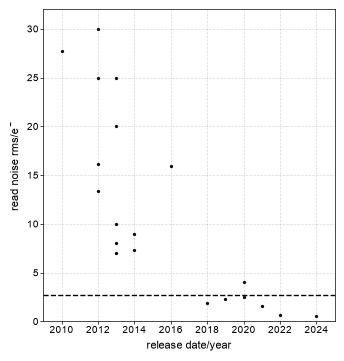

In [4]:
# Read noise the simulations show is low enough for S3M, drawn as the dashed line.
S3M_COMPATIBLE_READ_NOISE = 2.7  # RMS e-
YEAR_RANGE = (2009, 2025)

fig, ax = plotter.one_column_plot()
ax = plotter.scatter_plot(
    ax, camera_data['Year'], camera_data['RMS'],
    xlabel='release date/year', ylabel='read noise rms/e$^-$',
    xlim=YEAR_RANGE, ylim=(0, 32), linewidth=0.1, size=5,
)
ax.hlines(y=S3M_COMPATIBLE_READ_NOISE, xmin=YEAR_RANGE[0], xmax=YEAR_RANGE[1], ls='--', color='black', lw=1)

fig.savefig(OUT_ROOT / 'FigureSI_CameraHistory.svg', dpi=600, format='svg')
plt.show()